In [57]:
import pandas as pd
import numpy as np

In [58]:
mat = pd.read_csv("../Data/student-mat.csv", sep=";")
por = pd.read_csv("../Data/student-por.csv", sep=";")
print(mat.shape, por.shape)
mat.head()

(395, 33) (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


# Inspect the Dataset

In [59]:
mat["subject"] = "math"
por["subject"] = "portuguese"
df = pd.concat([mat, por], ignore_index=True)
print(df.shape)
df.info()

(1044, 34)
<class 'pandas.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      1044 non-null   str  
 1   sex         1044 non-null   str  
 2   age         1044 non-null   int64
 3   address     1044 non-null   str  
 4   famsize     1044 non-null   str  
 5   Pstatus     1044 non-null   str  
 6   Medu        1044 non-null   int64
 7   Fedu        1044 non-null   int64
 8   Mjob        1044 non-null   str  
 9   Fjob        1044 non-null   str  
 10  reason      1044 non-null   str  
 11  guardian    1044 non-null   str  
 12  traveltime  1044 non-null   int64
 13  studytime   1044 non-null   int64
 14  failures    1044 non-null   int64
 15  schoolsup   1044 non-null   str  
 16  famsup      1044 non-null   str  
 17  paid        1044 non-null   str  
 18  activities  1044 non-null   str  
 19  nursery     1044 non-null   str  
 20  higher      1044 non-null   st

## Missing Values

In [60]:
print("Missing:", df.isnull().sum().sum())
df.describe()

Missing: 0


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000
mean,16.726054,2.603448,2.387931,1.522989,1.970307,0.264368,3.935824,3.201149,3.156130,1.494253,2.284483,3.543103,4.434866,11.213602,11.246169,11.341954
std,1.239975,1.124907,1.099938,0.731727,0.834353,0.656142,0.933401,1.031507,1.152575,0.911714,1.285105,1.424703,6.210017,2.983394,3.285071,3.864796
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,9.000000,9.000000,10.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


There are **no missing values** in any column, so no imputation is needed.

## Check Duplicate Values

In [61]:
print("Duplicates:", df.duplicated().sum())
df.describe()

Duplicates: 0


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000
mean,16.726054,2.603448,2.387931,1.522989,1.970307,0.264368,3.935824,3.201149,3.156130,1.494253,2.284483,3.543103,4.434866,11.213602,11.246169,11.341954
std,1.239975,1.124907,1.099938,0.731727,0.834353,0.656142,0.933401,1.031507,1.152575,0.911714,1.285105,1.424703,6.210017,2.983394,3.285071,3.864796
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,9.000000,9.000000,10.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


There are **0 exact duplicate rows**.

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

## Analyze Numerical Features

In [63]:
numerical_cols = df.select_dtypes(include=np.number).columns

print("\n--- Numerical Feature Statistics ---")
print(df[numerical_cols].describe())


--- Numerical Feature Statistics ---
               age         Medu         Fedu   traveltime    studytime  \
count  1044.000000  1044.000000  1044.000000  1044.000000  1044.000000   
mean     16.726054     2.603448     2.387931     1.522989     1.970307   
std       1.239975     1.124907     1.099938     0.731727     0.834353   
min      15.000000     0.000000     0.000000     1.000000     1.000000   
25%      16.000000     2.000000     1.000000     1.000000     1.000000   
50%      17.000000     3.000000     2.000000     1.000000     2.000000   
75%      18.000000     4.000000     3.000000     2.000000     2.000000   
max      22.000000     4.000000     4.000000     4.000000     4.000000   

          failures       famrel     freetime        goout         Dalc  \
count  1044.000000  1044.000000  1044.000000  1044.000000  1044.000000   
mean      0.264368     3.935824     3.201149     3.156130     1.494253   
std       0.656142     0.933401     1.031507     1.152575     0.911714   

- **Age** ranges from 15 to 22 (average about 16.7).
- **Absences** average 4.4, but the maximum is 75. The data is heavily right-skewed, and most students have few absences.
- **Failures** are mostly 0. Only a small group of students have past failures.
- **Grades (G1, G2, G3)** average about 11 out of 20. G3 ranges from 0 to 20.

## Analyze Categorical Feature

In [77]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

print("\n--- Categorical Feature Summary ---")

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


--- Categorical Feature Summary ---

school:
school
GP    772
MS    272
Name: count, dtype: int64

sex:
sex
F    591
M    453
Name: count, dtype: int64

address:
address
U    759
R    285
Name: count, dtype: int64

famsize:
famsize
GT3    738
LE3    306
Name: count, dtype: int64

Pstatus:
Pstatus
T    923
A    121
Name: count, dtype: int64

Mjob:
Mjob
other       399
services    239
at_home     194
teacher     130
health       82
Name: count, dtype: int64

Fjob:
Fjob
other       584
services    292
teacher      65
at_home      62
health       41
Name: count, dtype: int64

reason:
reason
course        430
home          258
reputation    248
other         108
Name: count, dtype: int64

guardian:
guardian
mother    728
father    243
other      73
Name: count, dtype: int64

schoolsup:
schoolsup
no     925
yes    119
Name: count, dtype: int64

famsup:
famsup
yes    640
no     404
Name: count, dtype: int64

paid:
paid
no     824
yes    220
Name: count, dtype: int64

activities:
activities
n

/var/folders/_w/l6jxzwpj0c97m75m7sg17yy40000gn/T/ipykernel_13758/3263139848.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


- Most students attend **GP school** (772) rather than MS (272).
- Slightly more **female** (591) than male (453) students.
- Most live in **urban** areas (759) and have **internet access** (827).
- **91%** want to pursue higher education (955 yes vs 89 no).
- Few receive extra school support (119) or paid classes (220).

## Visualize Grade Distributions

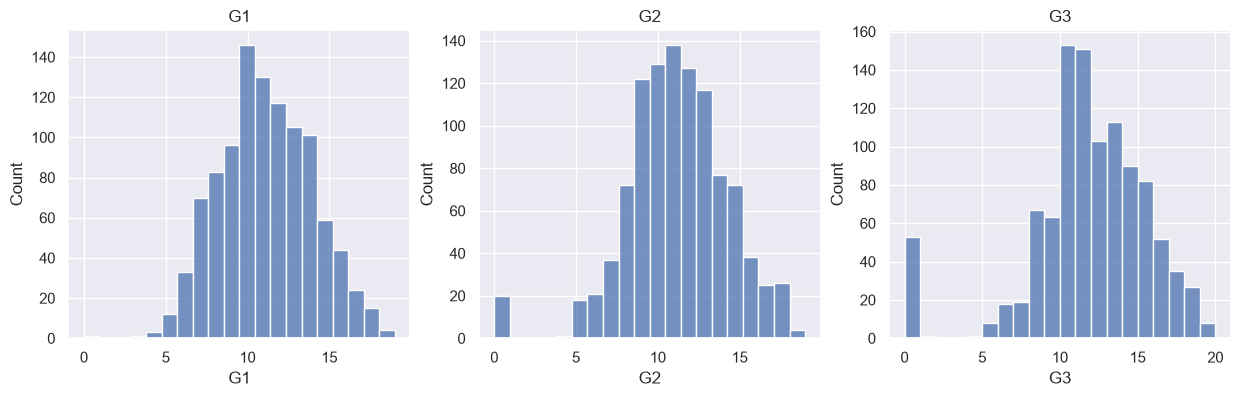

In [65]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, g in enumerate(["G1", "G2", "G3"]):
    sns.histplot(df[g], bins=20, ax=ax[i])
    ax[i].set_title(g)
plt.show()

- G1, G2 and G3 follow similar distributions, with most grades between 8 and 15.
- G3 has a noticeable spike at **0**, which likely represents students who dropped out or missed the final exam rather than a real score.

## Analyze Study Time


--- Average Final Grade by Study Time ---
                mean  count
studytime                  
1          10.580442    317
2          11.335984    503
3          12.493827    162
4          12.274194     62


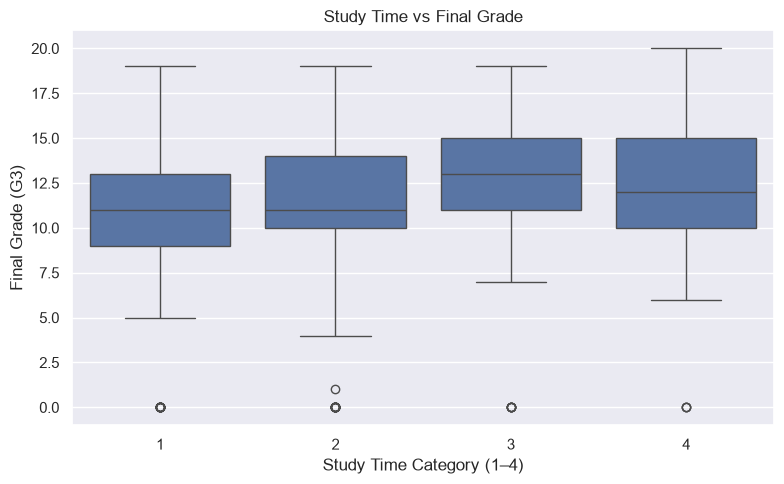

In [66]:
print("\n--- Average Final Grade by Study Time ---")
print(df.groupby("studytime")["G3"].agg(["mean", "count"]))

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="studytime", y="G3")
plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category (1–4)")
plt.ylabel("Final Grade (G3)")
plt.tight_layout()
plt.show()


- The average final grade increases with study time:
  - Study time 1: 10.58
  - Study time 2: 11.34
  - Study time 3: 12.49
  - Study time 4: 12.27
- More study time is generally linked to higher grades. The increase levels off at the highest category, which also has only 62 students.

## Analyze Student Absences

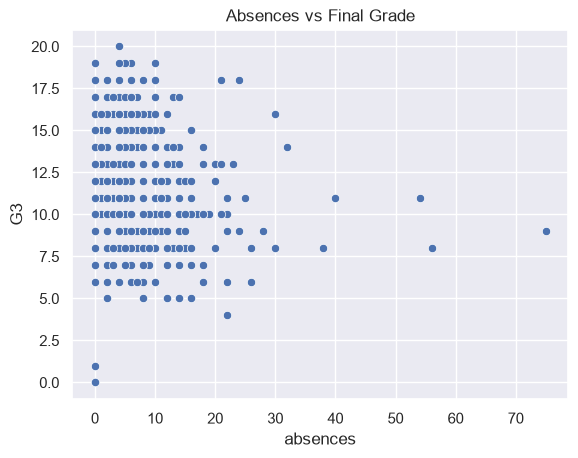

In [67]:
sns.scatterplot(x="absences", y="G3", data=df)
plt.title("Absences vs Final Grade")
plt.show()

- Most students have fewer than 10 absences.
- There is no strong linear relationship between absences and final grade.
- A few students have very high absences (up to 75), which are treated as outliers.

## Analyze Previous Grades


--- Previous and Final Grades ---
          G1        G2        G3
G1  1.000000  0.858739  0.809142
G2  0.858739  1.000000  0.910743
G3  0.809142  0.910743  1.000000


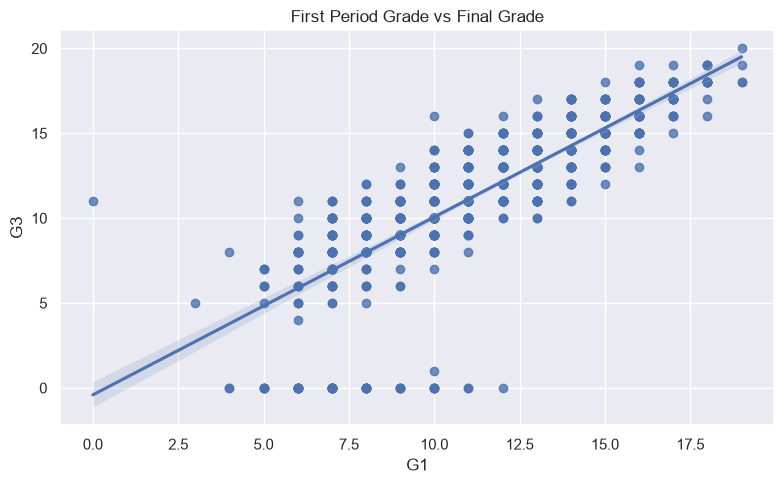

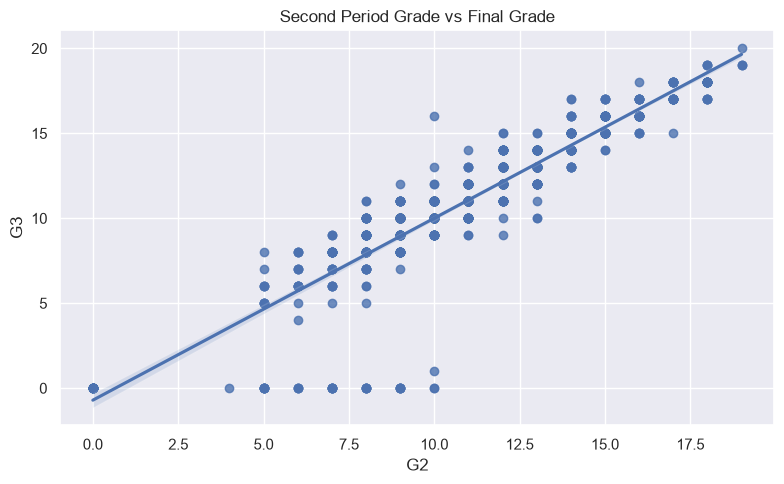

In [68]:
print("\n--- Previous and Final Grades ---")
print(df[["G1", "G2", "G3"]].corr())

plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="G1", y="G3")
plt.title("First Period Grade vs Final Grade")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="G2", y="G3")
plt.title("Second Period Grade vs Final Grade")
plt.tight_layout()
plt.show()


- Previous grades are strongly correlated with the final grade:
  - G1 vs G3: **0.81**
  - G2 vs G3: **0.91**
  - G1 vs G2: **0.86**
- G2 is the strongest predictor of G3. Including G1/G2 would make prediction easy, but it would not allow early prediction, so they are excluded from the input features.

## Analyze Feature Correlations

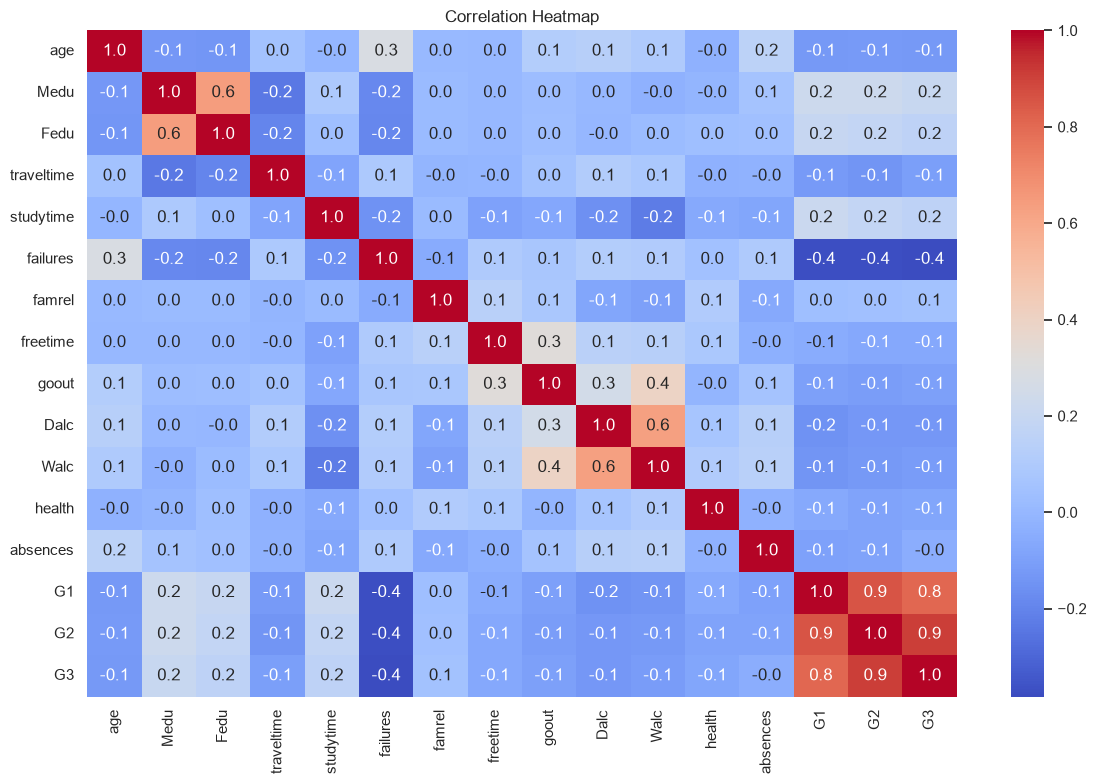

In [69]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    annot=True,
    fmt=".1f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

- G1, G2 and G3 are highly correlated with each other.
- **Failures** has the strongest negative correlation with G3, so students with past failures tend to score lower.
- Parents' education (Medu, Fedu) and study time show a weak positive correlation with G3.
- Alcohol consumption (Dalc, Walc), going out and absences show weak negative or near-zero correlation.

## Detect Outliers


--- IQR Outlier Detection ---
age: 2 potential outlier rows (lower=13.00, upper=21.00)
absences: 54 potential outlier rows (lower=-9.00, upper=15.00)
G1: 1 potential outlier rows (lower=3.00, upper=19.00)
G2: 20 potential outlier rows (lower=3.00, upper=19.00)
G3: 54 potential outlier rows (lower=4.00, upper=20.00)


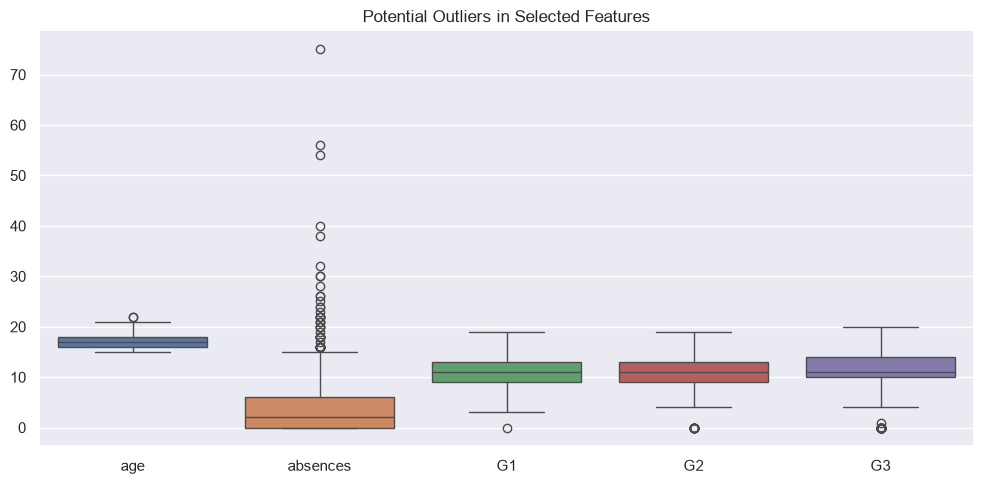

In [70]:
outlier_cols = ["age", "absences", "G1", "G2", "G3"]

print("\n--- IQR Outlier Detection ---")

for col in outlier_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(
        f"{col}: {len(outliers)} potential outlier rows "
        f"(lower={lower:.2f}, upper={upper:.2f})"
    )

plt.figure(figsize=(10, 5))
sns.boxplot(data=df[outlier_cols])
plt.title("Potential Outliers in Selected Features")
plt.tight_layout()
plt.show()

- age: 2 outliers (above 21)
- absences: 54 outliers (above 15)
- G1: 1 outlier, G2: 20 outliers
- G3: 54 outliers (below 4, mostly grades of 0)

## Select Input Features

In [71]:
target = "G3"

selected_features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "schoolsup",
    "famsup",
    "internet",
    "activities",
    "higher",
    "romantic",
    "health",
    "goout",
    "Dalc",
    "Walc"
]

X = df[selected_features].copy()
y = df[target].copy()

print("\n--- Selected Input Features ---")
print(X.columns.tolist())

print("\nTarget variable:", target)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)


--- Selected Input Features ---
['age', 'studytime', 'failures', 'absences', 'schoolsup', 'famsup', 'internet', 'activities', 'higher', 'romantic', 'health', 'goout', 'Dalc', 'Walc']

Target variable: G3
Feature matrix shape: (1044, 14)
Target shape: (1044,)


- 14 input features were selected, covering study habits, school support, social life and health.
- **G1 and G2 were excluded** so the model can predict performance early, before period grades are available.
- Final feature matrix: **1,044 rows × 14 columns**.

## Select the Target Variable

In [72]:
y = df["G3"]   # final grade (0–20)
print(y.describe())

count    1044.000000
mean       11.341954
std         3.864796
min         0.000000
25%        10.000000
50%        11.000000
75%        14.000000
max        20.000000
Name: G3, dtype: float64


- Target variable: **G3** (final grade, 0–20).
- Mean = 11.34, standard deviation = 3.86, median = 11.

## Encode Categorical Columns

In [75]:
cat_cols = X.select_dtypes(include="object").columns
print("Categorical columns:", list(cat_cols))

X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)
print(X_encoded.shape)
X_encoded.head()

Categorical columns: ['schoolsup', 'famsup', 'internet', 'activities', 'higher', 'romantic']
(1044, 14)


/var/folders/_w/l6jxzwpj0c97m75m7sg17yy40000gn/T/ipykernel_13758/2391901845.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns


,age,studytime,failures,absences,health,goout,Dalc,Walc,schoolsup_yes,famsup_yes,internet_yes,activities_yes,higher_yes,romantic_yes
0,18,2,0,6,3,4,1,1,1,0,0,0,1,0
1,17,2,0,4,3,3,1,1,0,1,1,0,1,0
2,15,2,3,10,3,2,2,3,1,0,1,0,1,0
3,15,3,0,2,5,2,1,1,0,1,1,1,1,1
4,16,2,0,4,5,2,1,2,0,1,0,0,1,0


- 6 categorical columns (schoolsup, famsup, internet, activities, higher, romantic) were one-hot encoded.
- Each is a yes/no column, so `drop_first=True` turns each into a single 0/1 column (e.g. `higher_yes`).
- The data is now fully numeric and ready for model training: **1,044 × 14**.